In [1]:
import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '2'

import random
import numpy as np
import matplotlib.pyplot as plt
import copy
import math
import time
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

SEEDS = [43, 44, 45, 46,47]
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
       torch.cuda.manual_seed(seed)
       torch.cuda.manual_seed_all(seed)
       torch.backends.cudnn.deterministic = False
       torch.backends.cudnn.benchmark = True

set_seed(42)

# Setup

In [2]:
PATH = "/home/jovyan/work/UFSC/ubiquos_tomato_village/dataset/tomato_village/tomato_village/Variant-a(Multiclass Classification)"

EPOCHS = 100
PATIENCE_ES = 100

BATCH_SIZE = 64


LR = 1e-3
MIN_LR = 1e-7
GRAD_CLIP = 1.0

IMG_SIZE = (224, 224)
MODEL_SAVE_PATH = "best_model_seed_{seed}.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {DEVICE}")

Device: cuda


# Dataset

In [3]:
NORMALIZE_MEAN = (0.485, 0.456, 0.406)
NORMALIZE_STD = (0.229, 0.224, 0.225)

In [4]:
train_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.RandomHorizontalFlip(p=0.1),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

val_test_transforms = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])

In [5]:
train_dir = os.path.join(PATH, "train")
val_dir = os.path.join(PATH, "val")
test_dir = os.path.join(PATH, "test")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=val_test_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transforms)

class_names = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

if val_dataset.class_to_idx != class_to_idx:
    raise ValueError("As classes de treino e validação não estão alinhadas")

if test_dataset.class_to_idx != class_to_idx:
    raise ValueError("As classes de treino e teste não estão alinhadas")

pin_memory = DEVICE.type == "cuda"

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=pin_memory,
    persistent_workers=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=pin_memory,
    persistent_workers=True,
)

print(f"Classes: {len(class_names)}")
print(
    f"Train: {len(train_dataset)} | "
    f"Val: {len(val_dataset)} | "
    f"Test: {len(test_dataset)}"
)

Classes: 8
Train: 3162 | Val: 902 | Test: 461


Distribuicao no treino:
  Early_blight                  : 347
  Healthy                       : 151
  Late_blight                   : 632
  Leaf Miner                    : 716
  Magnesium Deficiency          : 654
  Nitrogen Deficiency           : 251
  Pottassium Deficiency         : 50
  Spotted Wilt Virus            : 361


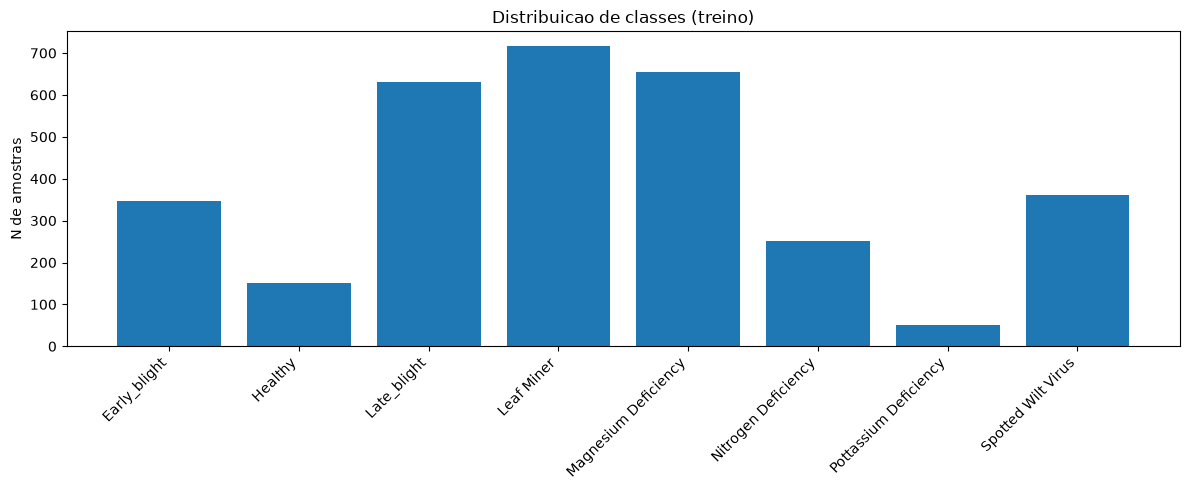

Class weights: [0.844589352607727, 1.2803298234939575, 0.625823438167572, 0.5879681706428528, 0.615207314491272, 0.9930554032325745, 2.224976062774658, 0.8280503749847412]


In [6]:
train_targets = np.asarray(train_dataset.targets)
train_counts = np.bincount(train_targets, minlength=len(class_names))

print("Distribuicao no treino:")
for name, count in zip(class_names, train_counts):
    print(f"  {name:30s}: {count}")

plt.figure(figsize=(12, 5))
plt.bar(class_names, train_counts)
plt.xticks(rotation=45, ha='right')
plt.ylabel("N de amostras")
plt.title("Distribuicao de classes (treino)")
plt.tight_layout()
plt.show()

class_weights = len(train_targets) / (
    len(class_names) * train_counts
)

class_weights = np.sqrt(class_weights)
class_weights = class_weights / class_weights.mean()

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)
print(f"Class weights: {class_weights.tolist()}")

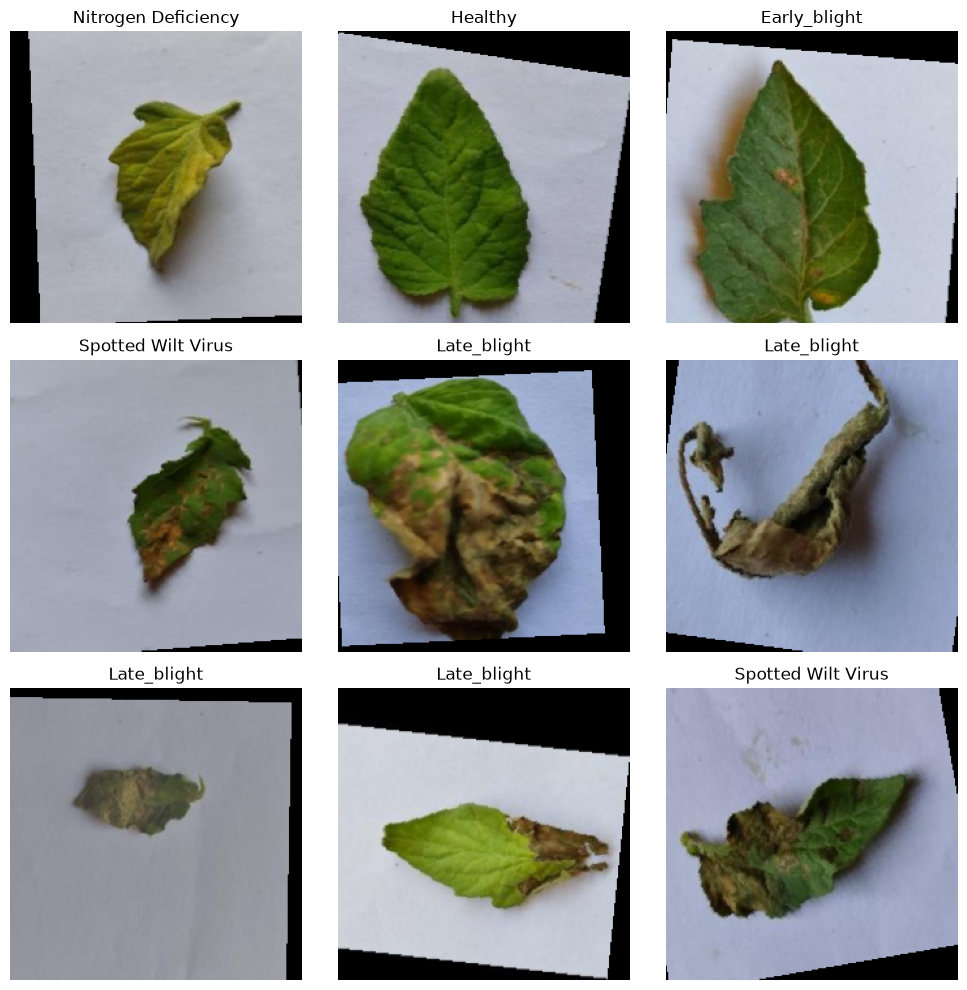

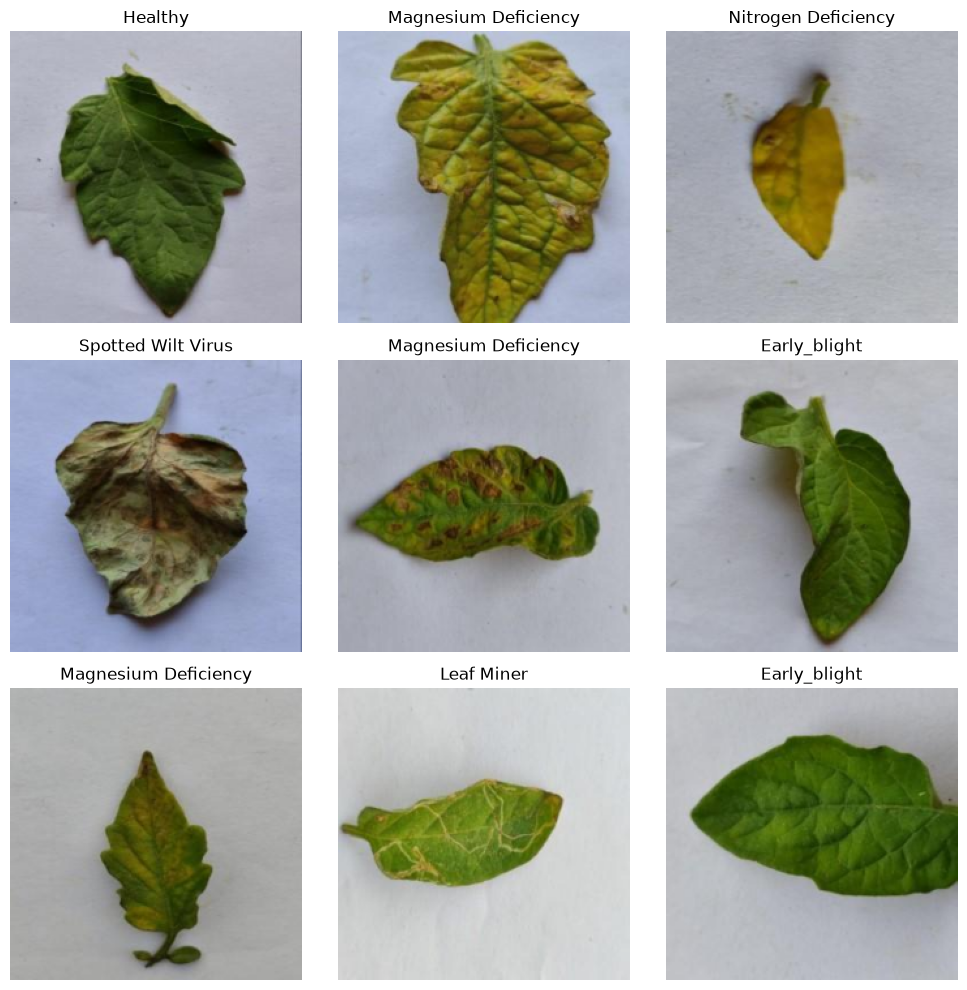

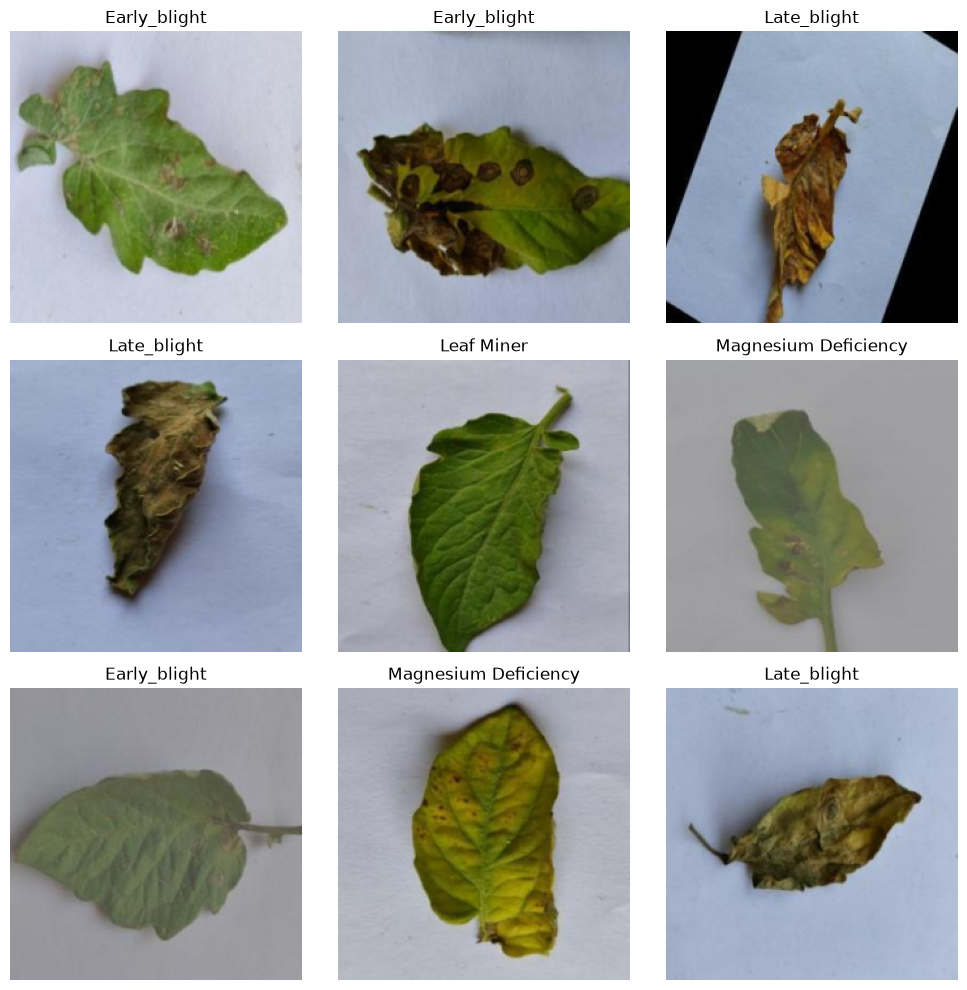

In [7]:
def plot_samples(dataset, class_names, num_samples=9):
    cols = 3
    rows = math.ceil(num_samples / cols)
    plt.figure(figsize=(10, 10))
    
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    indices = random.sample(range(len(dataset)), num_samples)
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        img_np = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        
        ax = plt.subplot(rows, cols, i + 1)
        plt.imshow(img_np)
        plt.title(class_names[label])
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()

plot_samples(train_dataset, class_names)
plot_samples(test_dataset, class_names)
plot_samples(val_dataset, class_names)

# Model

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ConvDPUnit(nn.Module):
    def __init__(self, in_channels, out_channels, with_bn_relu=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 1, 1, 0, bias=True)
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            3,
            1,
            1,
            bias=True,
            groups=out_channels
        )
        self.with_bn_relu = with_bn_relu
        if with_bn_relu:
            self.bn = nn.BatchNorm2d(out_channels)
            self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        if self.with_bn_relu:
            x = self.bn(x)
            x = self.relu(x)
        return x


class ConvHead(nn.Module):
    def __init__(self, in_channels, mid_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, mid_channels, 3, 2, 1, bias=True)
        self.bn = nn.BatchNorm2d(mid_channels)
        self.relu = nn.ReLU(inplace=True)
        self.proj = ConvDPUnit(mid_channels, out_channels)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        return self.proj(x)


class Conv4LayerBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = ConvDPUnit(in_channels, in_channels)
        self.conv2 = ConvDPUnit(in_channels, out_channels)

    def forward(self, x):
        x = self.conv1(x)
        return self.conv2(x)


class YuNetBackbone(nn.Module):
    def __init__(self):
        super().__init__()
        self.downsample_idx = {0, 2, 3, 4}
        self.out_idx = {3, 4, 5}
        self.stages = nn.ModuleList([
            ConvHead(3, 16, 16),
            Conv4LayerBlock(16, 64),
            Conv4LayerBlock(64, 64),
            Conv4LayerBlock(64, 64),
            Conv4LayerBlock(64, 64),
            Conv4LayerBlock(64, 64),
        ])

    def forward(self, x):
        outputs = []
        for idx, stage in enumerate(self.stages):
            x = stage(x)
            if idx in self.out_idx:
                outputs.append(x)
            if idx in self.downsample_idx:
                x = F.max_pool2d(x, 2)
        return outputs


class TFPN(nn.Module):
    def __init__(self, channels=64):
        super().__init__()
        self.lateral_convs = nn.ModuleList([
            ConvDPUnit(channels, channels),
            ConvDPUnit(channels, channels),
            ConvDPUnit(channels, channels),
        ])

    def forward(self, feats):
        feats = list(feats)
        for idx in range(len(feats) - 1, 0, -1):
            feats[idx] = self.lateral_convs[idx](feats[idx])
            feats[idx - 1] = feats[idx - 1] + F.interpolate(
                feats[idx],
                size=feats[idx - 1].shape[-2:],
                mode='nearest'
            )
        feats[0] = self.lateral_convs[0](feats[0])
        return feats


class YuNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.backbone = YuNetBackbone()
        self.neck = TFPN(64)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(64 * 3, num_classes)
        self._init_weights()

    def _init_weights(self):
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                if layer.bias is not None:
                    nn.init.xavier_normal_(layer.weight.data)
                    layer.bias.data.fill_(0.02)
                else:
                    layer.weight.data.normal_(0, 0.01)
            elif isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)
            elif isinstance(layer, nn.BatchNorm2d):
                layer.weight.data.fill_(1)
                layer.bias.data.zero_()

    def forward(self, x):
        feats = self.neck(self.backbone(x))
        x = torch.cat([self.pool(feat).flatten(1) for feat in feats], dim=1)
        return self.classifier(x)

In [9]:
model = YuNet(len(class_names)).to(DEVICE)

In [10]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {total_params:,}")

Total Parameters: 59,016


# Train

In [11]:
from sklearn.metrics import f1_score


def create_train_loader(seed):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=4,
        pin_memory=pin_memory,
        persistent_workers=True,
        generator=generator,
    )


def create_training_components(train_loader):
    model = YuNet(len(class_names)).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=1e-6, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=LR,
        steps_per_epoch=len(train_loader),
        epochs=EPOCHS,
        div_factor=1000,
        final_div_factor=1,
    )
    return model, optimizer, criterion, scheduler

In [12]:
from tqdm.auto import tqdm


def run_seed(seed):
    set_seed(seed)
    train_loader = create_train_loader(seed)
    model, optimizer, criterion, scheduler = create_training_components(train_loader)
    checkpoint_path = MODEL_SAVE_PATH.format(seed=seed)

    best_acc = 0.0
    best_epoch = 0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in tqdm(range(EPOCHS), desc=f"Seed {seed}"):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            scheduler.step()
            running_loss += loss.item() * inputs.size(0)
            predicted = outputs.argmax(dim=1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_dataset)
        epoch_acc = correct_train / total_train
        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)

        model.eval()
        val_loss_running = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss_running += loss.item() * inputs.size(0)
                predicted = outputs.argmax(dim=1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = val_loss_running / len(val_dataset)
        val_acc = correct_val / total_val
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        tqdm.write(
            f"seed={seed} [{epoch + 1:03d}/{EPOCHS}] "
            f"train_loss={epoch_loss:.4f} train_acc={epoch_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
            f"lr={optimizer.param_groups[0]['lr']:.2e}"
        )

        if val_acc > best_acc:
            best_acc = val_acc
            best_epoch = epoch + 1
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE_ES:
                tqdm.write(f"Seed {seed}: early stopping na época {epoch + 1}")
                break

    model.load_state_dict(best_model_wts)
    model.eval()
    test_labels = []
    test_predictions = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(DEVICE)
            predictions = model(inputs).argmax(dim=1).cpu().numpy()
            test_predictions.extend(predictions.tolist())
            test_labels.extend(labels.numpy().tolist())

    test_accuracy = float(np.mean(np.asarray(test_predictions) == np.asarray(test_labels)))
    test_macro_f1 = f1_score(test_labels, test_predictions, average="macro", zero_division=0)
    test_class_f1 = f1_score(test_labels, test_predictions, average=None, zero_division=0)

    result = {
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_acc,
        "test_accuracy": test_accuracy,
        "test_macro_f1": test_macro_f1,
        "test_class_f1": test_class_f1,
        "test_labels": test_labels,
        "test_predictions": test_predictions,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
    }
    return model, result




In [13]:
seed_results = []
for seed in SEEDS:
    print(f"\nIniciando seed {seed}")
    model, result = run_seed(seed)
    seed_results.append(result)
    print(
        f"Seed {seed}: val_acc={result['best_val_accuracy']:.4f} | "
        f"test_acc={result['test_accuracy']:.4f} | "
        f"test_macro_f1={result['test_macro_f1']:.4f}"
    )


Iniciando seed 43


Seed 43:   0%|          | 0/100 [00:00<?, ?it/s]

seed=43 [001/100] train_loss=4.9643 train_acc=0.0787 | val_loss=3.5558 val_acc=0.0798 | lr=3.74e-06
seed=43 [002/100] train_loss=4.9105 train_acc=0.0791 | val_loss=3.8156 val_acc=0.0776 | lr=1.19e-05
seed=43 [003/100] train_loss=4.7360 train_acc=0.0794 | val_loss=3.6171 val_acc=0.0776 | lr=2.55e-05
seed=43 [004/100] train_loss=4.4241 train_acc=0.0791 | val_loss=3.2131 val_acc=0.0809 | lr=4.42e-05
seed=43 [005/100] train_loss=3.8249 train_acc=0.0822 | val_loss=2.6741 val_acc=0.1053 | lr=6.80e-05
seed=43 [006/100] train_loss=3.1003 train_acc=0.0987 | val_loss=2.1989 val_acc=0.1630 | lr=9.65e-05
seed=43 [007/100] train_loss=2.4309 train_acc=0.2255 | val_loss=1.8561 val_acc=0.3359 | lr=1.29e-04
seed=43 [008/100] train_loss=1.9811 train_acc=0.3969 | val_loss=1.7366 val_acc=0.3858 | lr=1.66e-04
seed=43 [009/100] train_loss=1.7075 train_acc=0.4507 | val_loss=1.5953 val_acc=0.4701 | lr=2.07e-04
seed=43 [010/100] train_loss=1.5586 train_acc=0.4785 | val_loss=1.4264 val_acc=0.4922 | lr=2.51e-04


Seed 44:   0%|          | 0/100 [00:00<?, ?it/s]

seed=44 [001/100] train_loss=2.7195 train_acc=0.0778 | val_loss=2.3275 val_acc=0.2262 | lr=3.74e-06
seed=44 [002/100] train_loss=2.6992 train_acc=0.0857 | val_loss=2.3186 val_acc=0.0887 | lr=1.19e-05
seed=44 [003/100] train_loss=2.6303 train_acc=0.0870 | val_loss=2.2622 val_acc=0.0909 | lr=2.55e-05
seed=44 [004/100] train_loss=2.4738 train_acc=0.1037 | val_loss=2.1463 val_acc=0.0987 | lr=4.42e-05
seed=44 [005/100] train_loss=2.2680 train_acc=0.1442 | val_loss=2.0409 val_acc=0.1563 | lr=6.80e-05
seed=44 [006/100] train_loss=2.0674 train_acc=0.2068 | val_loss=1.9128 val_acc=0.2173 | lr=9.65e-05
seed=44 [007/100] train_loss=1.8881 train_acc=0.3261 | val_loss=1.7603 val_acc=0.3714 | lr=1.29e-04
seed=44 [008/100] train_loss=1.7700 train_acc=0.3868 | val_loss=1.6488 val_acc=0.4113 | lr=1.66e-04
seed=44 [009/100] train_loss=1.6703 train_acc=0.4190 | val_loss=1.5563 val_acc=0.4468 | lr=2.07e-04
seed=44 [010/100] train_loss=1.5832 train_acc=0.4428 | val_loss=1.5750 val_acc=0.3958 | lr=2.51e-04


Seed 45:   0%|          | 0/100 [00:00<?, ?it/s]

seed=45 [001/100] train_loss=3.3127 train_acc=0.1578 | val_loss=3.9670 val_acc=0.1142 | lr=3.74e-06
seed=45 [002/100] train_loss=3.3000 train_acc=0.1528 | val_loss=3.4230 val_acc=0.1619 | lr=1.19e-05
seed=45 [003/100] train_loss=3.1632 train_acc=0.1534 | val_loss=3.2781 val_acc=0.1696 | lr=2.55e-05
seed=45 [004/100] train_loss=2.9991 train_acc=0.1559 | val_loss=3.1306 val_acc=0.1552 | lr=4.42e-05
seed=45 [005/100] train_loss=2.8210 train_acc=0.1771 | val_loss=2.9714 val_acc=0.1585 | lr=6.80e-05
seed=45 [006/100] train_loss=2.5815 train_acc=0.1879 | val_loss=2.6020 val_acc=0.1951 | lr=9.65e-05
seed=45 [007/100] train_loss=2.3230 train_acc=0.2299 | val_loss=2.1217 val_acc=0.2805 | lr=1.29e-04
seed=45 [008/100] train_loss=1.9838 train_acc=0.2777 | val_loss=1.6623 val_acc=0.4024 | lr=1.66e-04
seed=45 [009/100] train_loss=1.7121 train_acc=0.3650 | val_loss=1.6014 val_acc=0.4080 | lr=2.07e-04
seed=45 [010/100] train_loss=1.5635 train_acc=0.4355 | val_loss=1.5390 val_acc=0.3758 | lr=2.51e-04


Seed 46:   0%|          | 0/100 [00:00<?, ?it/s]

seed=46 [001/100] train_loss=5.4597 train_acc=0.1142 | val_loss=4.2345 val_acc=0.1142 | lr=3.74e-06
seed=46 [002/100] train_loss=5.4122 train_acc=0.1142 | val_loss=4.8087 val_acc=0.1142 | lr=1.19e-05
seed=46 [003/100] train_loss=5.2234 train_acc=0.1145 | val_loss=4.4728 val_acc=0.1142 | lr=2.55e-05
seed=46 [004/100] train_loss=4.8045 train_acc=0.1142 | val_loss=3.7961 val_acc=0.1142 | lr=4.42e-05
seed=46 [005/100] train_loss=4.0746 train_acc=0.1157 | val_loss=3.2145 val_acc=0.1164 | lr=6.80e-05
seed=46 [006/100] train_loss=3.1724 train_acc=0.1262 | val_loss=2.5355 val_acc=0.1308 | lr=9.65e-05
seed=46 [007/100] train_loss=2.3070 train_acc=0.1752 | val_loss=1.9564 val_acc=0.2905 | lr=1.29e-04
seed=46 [008/100] train_loss=1.8229 train_acc=0.3153 | val_loss=1.6765 val_acc=0.4180 | lr=1.66e-04
seed=46 [009/100] train_loss=1.5767 train_acc=0.4456 | val_loss=1.5144 val_acc=0.4557 | lr=2.07e-04
seed=46 [010/100] train_loss=1.4339 train_acc=0.4889 | val_loss=1.3515 val_acc=0.5011 | lr=2.51e-04


Seed 47:   0%|          | 0/100 [00:00<?, ?it/s]

seed=47 [001/100] train_loss=3.6680 train_acc=0.1407 | val_loss=4.6928 val_acc=0.1996 | lr=3.74e-06
seed=47 [002/100] train_loss=3.6118 train_acc=0.1442 | val_loss=3.4005 val_acc=0.1807 | lr=1.19e-05
seed=47 [003/100] train_loss=3.5071 train_acc=0.1480 | val_loss=3.1734 val_acc=0.1796 | lr=2.55e-05
seed=47 [004/100] train_loss=3.3083 train_acc=0.1575 | val_loss=2.8292 val_acc=0.2018 | lr=4.42e-05
seed=47 [005/100] train_loss=3.0385 train_acc=0.1869 | val_loss=2.5339 val_acc=0.2095 | lr=6.80e-05
seed=47 [006/100] train_loss=2.6756 train_acc=0.2293 | val_loss=2.1758 val_acc=0.2860 | lr=9.65e-05
seed=47 [007/100] train_loss=2.3073 train_acc=0.2973 | val_loss=1.9008 val_acc=0.3104 | lr=1.29e-04
seed=47 [008/100] train_loss=1.9851 train_acc=0.3558 | val_loss=1.7503 val_acc=0.3714 | lr=1.66e-04
seed=47 [009/100] train_loss=1.7890 train_acc=0.4039 | val_loss=1.7311 val_acc=0.3792 | lr=2.07e-04
seed=47 [010/100] train_loss=1.6660 train_acc=0.4320 | val_loss=1.6252 val_acc=0.4080 | lr=2.51e-04


Resultados por seed:
seed=43 | época=086 | val_acc=0.8780 | test_acc=0.8915 | test_macro_f1=0.8757
seed=44 | época=094 | val_acc=0.8714 | test_acc=0.8482 | test_macro_f1=0.8293
seed=45 | época=087 | val_acc=0.8636 | test_acc=0.8677 | test_macro_f1=0.8474
seed=46 | época=089 | val_acc=0.8769 | test_acc=0.8894 | test_macro_f1=0.8722
seed=47 | época=092 | val_acc=0.8747 | test_acc=0.8807 | test_macro_f1=0.8596

Resumo:
Val accuracy:   0.8729 ± 0.0058
Test accuracy:  0.8755 ± 0.0179
Test macro-F1:  0.8568 ± 0.0190

F1 por classe:
Early_blight                  : 0.8305 ± 0.0539
Healthy                       : 0.7291 ± 0.0684
Late_blight                   : 0.9027 ± 0.0112
Leaf Miner                    : 0.8877 ± 0.0241
Magnesium Deficiency          : 0.9376 ± 0.0113
Nitrogen Deficiency           : 0.9398 ± 0.0192
Pottassium Deficiency         : 0.8764 ± 0.0389
Spotted Wilt Virus            : 0.7510 ± 0.0549


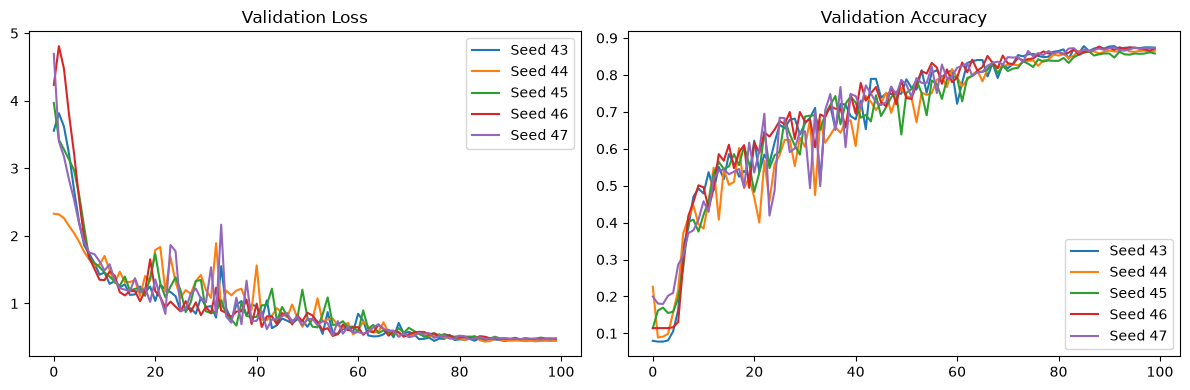

In [14]:
val_accuracies = np.asarray([result["best_val_accuracy"] for result in seed_results])
test_accuracies = np.asarray([result["test_accuracy"] for result in seed_results])
test_macro_f1_scores = np.asarray([result["test_macro_f1"] for result in seed_results])
test_class_f1_scores = np.stack([result["test_class_f1"] for result in seed_results])

print("Resultados por seed:")
for result in seed_results:
    print(
        f"seed={result['seed']} | época={result['best_epoch']:03d} | "
        f"val_acc={result['best_val_accuracy']:.4f} | "
        f"test_acc={result['test_accuracy']:.4f} | "
        f"test_macro_f1={result['test_macro_f1']:.4f}"
    )

print("\nResumo:")
print(f"Val accuracy:   {val_accuracies.mean():.4f} ± {val_accuracies.std(ddof=1):.4f}")
print(f"Test accuracy:  {test_accuracies.mean():.4f} ± {test_accuracies.std(ddof=1):.4f}")
print(f"Test macro-F1:  {test_macro_f1_scores.mean():.4f} ± {test_macro_f1_scores.std(ddof=1):.4f}")

print("\nF1 por classe:")
for class_name, scores in zip(class_names, test_class_f1_scores.T):
    print(f"{class_name:30s}: {scores.mean():.4f} ± {scores.std(ddof=1):.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for result in seed_results:
    plt.plot(result["val_losses"], label=f"Seed {result['seed']}")
plt.legend()
plt.title("Validation Loss")

plt.subplot(1, 2, 2)
for result in seed_results:
    plt.plot(result["val_accs"], label=f"Seed {result['seed']}")
plt.legend()
plt.title("Validation Accuracy")
plt.tight_layout()
plt.show()

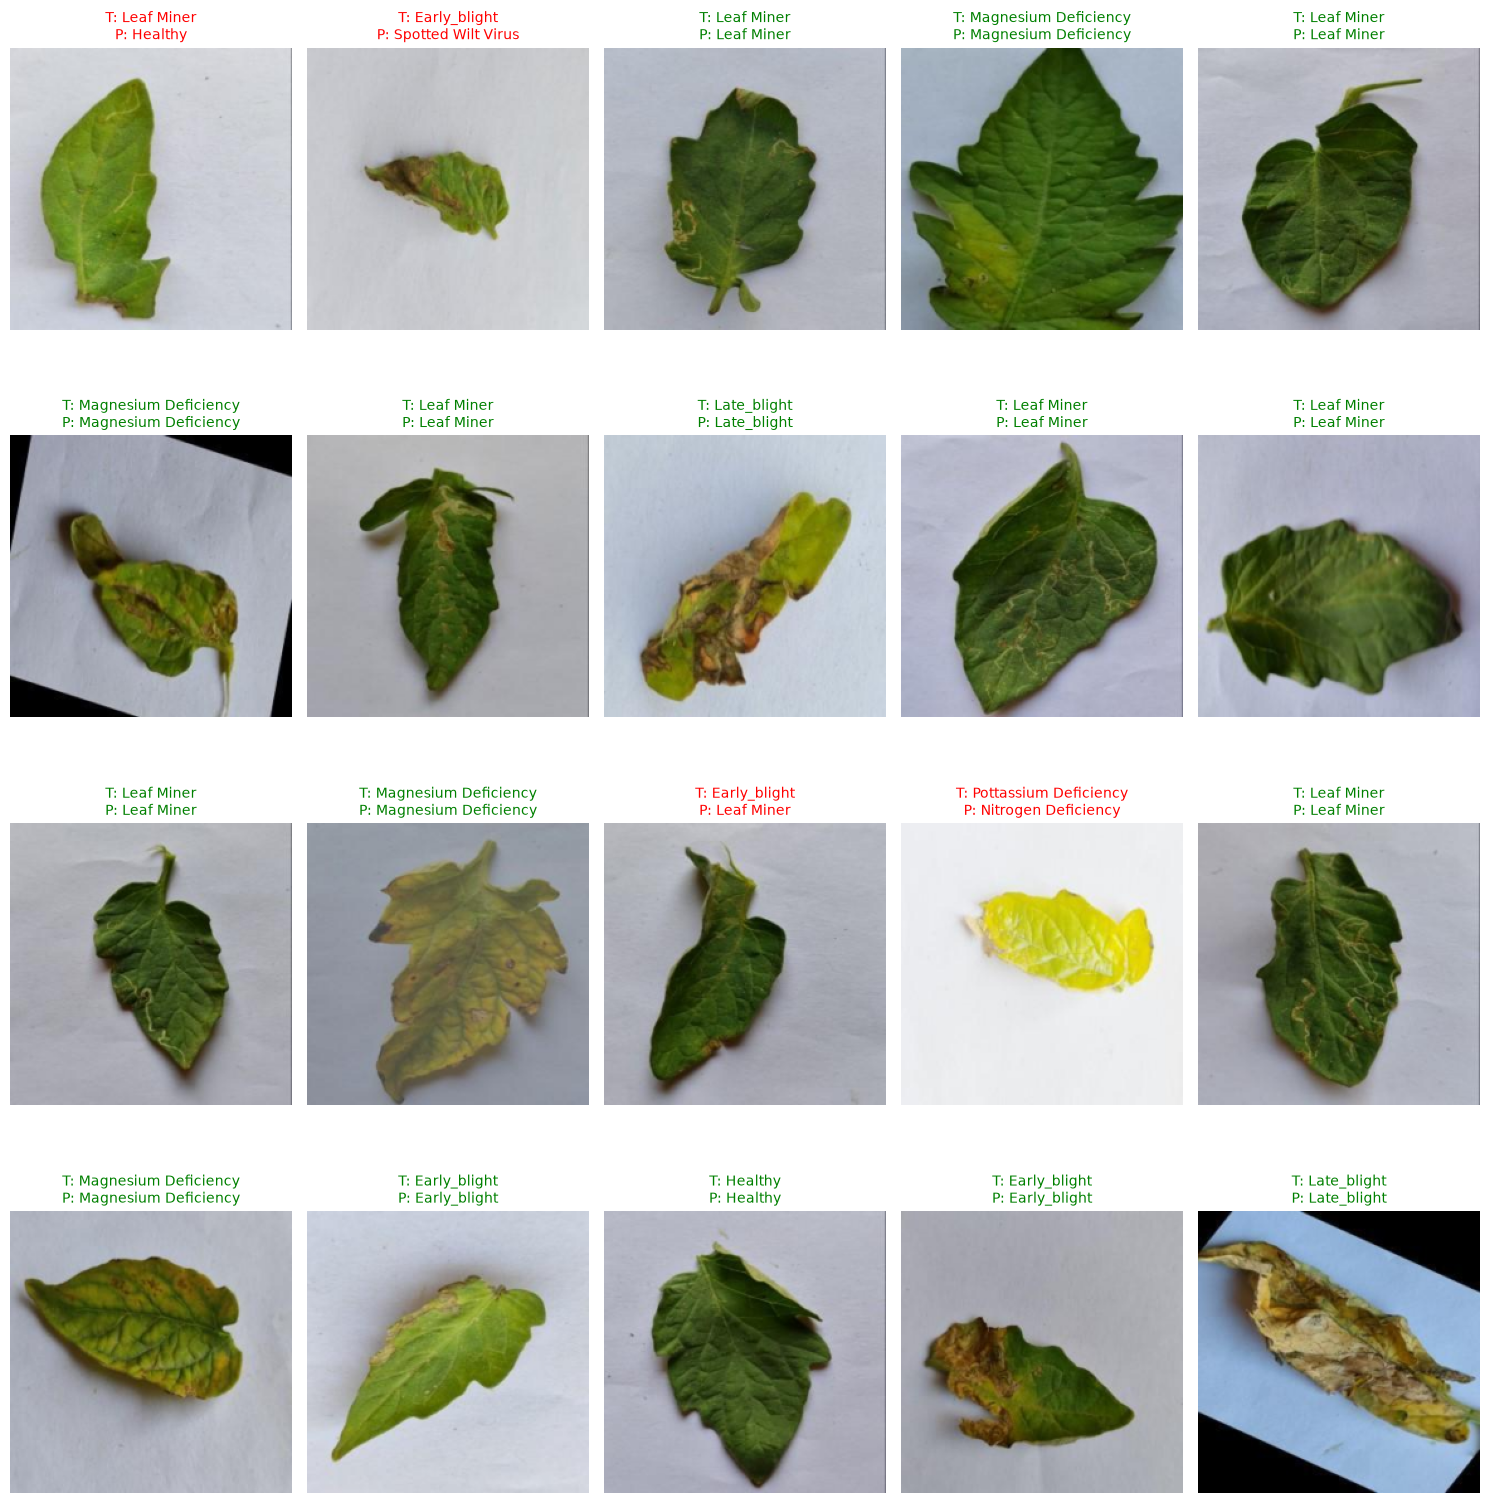

In [15]:
def predict_and_plot(model, dataset, classes, num_samples=10):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    model.eval()
    indices = random.sample(range(len(dataset)), num_samples)

    cols = 5
    rows = math.ceil(num_samples / cols)

    plt.figure(figsize=(15, 4 * rows))
    for i, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        img_input = img_tensor.unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            output = model(img_input)
            pred = output.argmax(dim=1).item()

        img_np = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img_np)

        color = 'green' if pred == label else 'red'
        plt.title(f"T: {classes[label]}\nP: {classes[pred]}", color=color, fontsize=10)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

predict_and_plot(model, test_dataset, class_names, num_samples=20)


Seed 43
                       precision    recall  f1-score   support

         Early_blight     0.9318    0.8200    0.8723        50
              Healthy     0.6552    0.8636    0.7451        22
          Late_blight     0.8947    0.9239    0.9091        92
           Leaf Miner     0.9271    0.8558    0.8900       104
 Magnesium Deficiency     0.9381    0.9579    0.9479        95
  Nitrogen Deficiency     0.9722    0.9459    0.9589        37
Pottassium Deficiency     0.8750    0.8750    0.8750         8
   Spotted Wilt Virus     0.7857    0.8302    0.8073        53

             accuracy                         0.8915       461
            macro avg     0.8725    0.8840    0.8757       461
         weighted avg     0.8969    0.8915    0.8927       461


Seed 44
                       precision    recall  f1-score   support

         Early_blight     0.8537    0.7000    0.7692        50
              Healthy     0.5833    0.6364    0.6087        22
          Late_blight     0.9121 

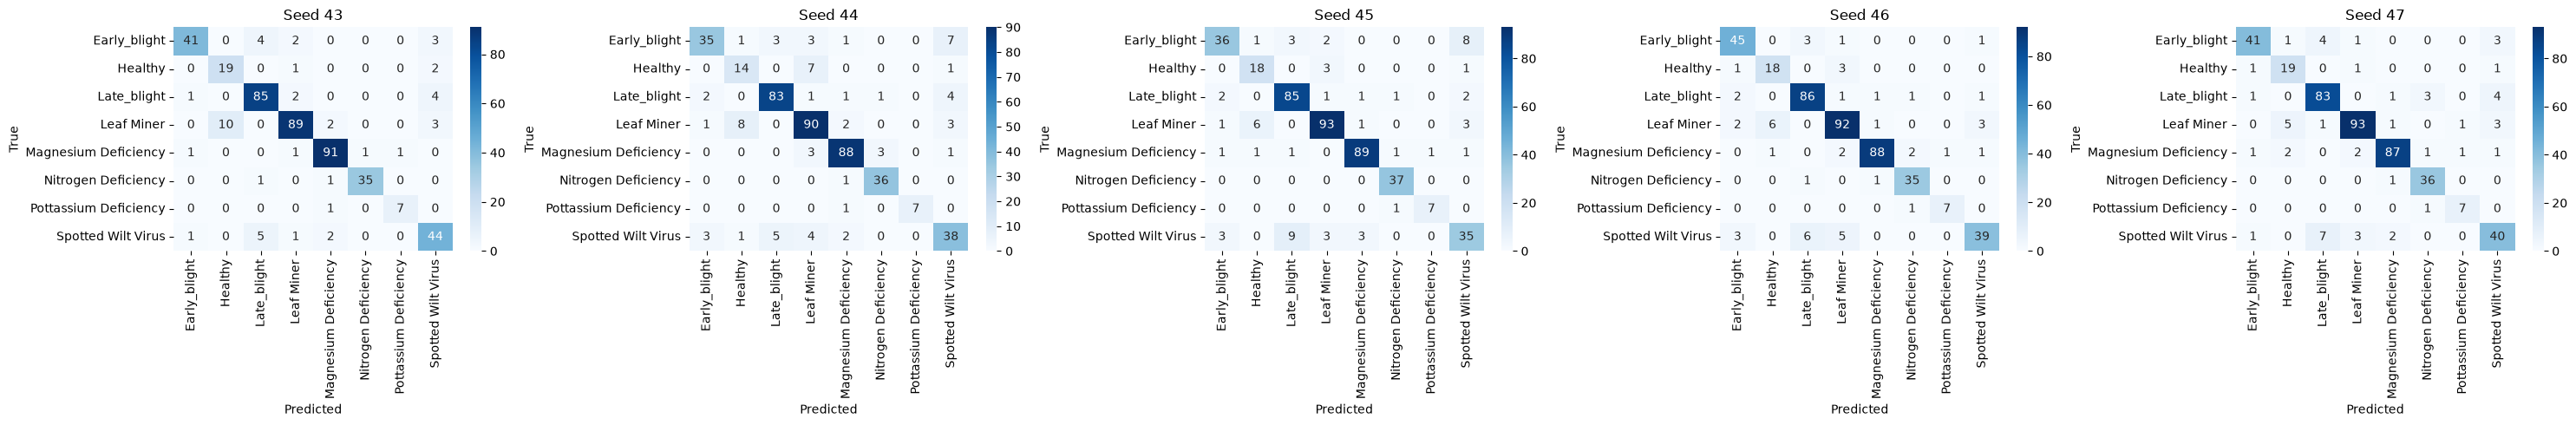

In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

for result in seed_results:
    print(f"\nSeed {result['seed']}")
    print(
        classification_report(
            result["test_labels"],
            result["test_predictions"],
            target_names=class_names,
            digits=4,
            zero_division=0,
        )
    )

fig, axes = plt.subplots(1, len(seed_results), figsize=(6 * len(seed_results), 5))
for axis, result in zip(axes, seed_results):
    cm = confusion_matrix(result["test_labels"], result["test_predictions"])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=axis,
    )
    axis.set_title(f"Seed {result['seed']}")
    axis.set_xlabel("Predicted")
    axis.set_ylabel("True")
plt.tight_layout()
plt.show()

# Export Edge AI

In [17]:
import copy
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch
import litert_torch

from ai_edge_litert.interpreter import Interpreter
from ai_edge_quantizer import quantizer, recipe


EXPORT_DIR = Path("tflite_models")
EXPORT_DIR.mkdir(exist_ok=True)

NUM_CALIB_SAMPLES = 100
EXPORT_SEED = SEEDS[-1]
LOG_DIR = Path("logs")
LOG_DIR.mkdir(exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
LOG_PATH = LOG_DIR / f"yunet_seed_experiment_{RUN_ID}.json"

FP32_PATH = EXPORT_DIR / "model_fp32.tflite"
INT8A16_PATH = EXPORT_DIR / "model_int8a16.tflite"
INT8_PATH = EXPORT_DIR / "model_int8.tflite"

calibration_dataset = datasets.ImageFolder(train_dir, transform=val_test_transforms)

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.10.0+cu128).


In [18]:
export_model = copy.deepcopy(model).cpu().eval()

sample_image = test_dataset[0][0]
sample_inputs = (sample_image.unsqueeze(0).cpu(),)

print(sample_inputs[0].shape)

torch.Size([1, 3, 224, 224])


In [19]:
edge_model = litert_torch.convert(export_model, sample_inputs)
edge_model.export(str(FP32_PATH))

print(f"FP32: {FP32_PATH.stat().st_size / 1024 / 1024:.2f} MB")

(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

/opt/conda/lib/python3.11/copyreg.py:105: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


(00:01) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:00)

(00:01) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:01)

... (19 outputs left out)

(00:00) [START] Write Model to tflite_models/model_fp32.tflite

I0000 00:00:1788606071.723543    2569 flatbuffer_export.cc:4342] Estimated count of arithmetic ops: 123.700 M  ops, equivalently 61.850 M  MACs


(00:00) [ DONE] Write Model to tflite_models/model_fp32.tflite (+00:00)

FP32: 0.25 MB


In [20]:
def create_calibration_data(model_path, dataset, num_samples=200, seed=42):
    interpreter = Interpreter(model_path=str(model_path))
    signatures = interpreter.get_signature_list()

    if len(signatures) != 1:
        raise ValueError(f"Esperada uma signature, encontradas: {list(signatures)}")

    signature_name, signature = next(iter(signatures.items()))
    input_names = signature["inputs"]

    if len(input_names) != 1:
        raise ValueError(f"Esperada uma entrada, encontradas: {input_names}")

    input_name = input_names[0]

    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset), generator=generator)[:min(num_samples, len(dataset))].tolist()

    samples = []

    for index in indices:
        image = dataset[index][0]
        samples.append({input_name: image.unsqueeze(0).cpu().numpy().astype(np.float32)})

    return {signature_name: samples}



def quantize_static(fp32_path, output_path, calibration_data, quantization_recipe):
    qt = quantizer.Quantizer(str(fp32_path))
    qt.load_quantization_recipe(quantization_recipe())
    calibration_result = qt.calibrate(calibration_data)
    result = qt.quantize(calibration_result)
    result.export_model(str(output_path), overwrite=True)

    print(f"{output_path.name}: {output_path.stat().st_size / 1024 / 1024:.2f} MB")

    
def inspect_tflite(model_path):
    interpreter = Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    input_info = interpreter.get_input_details()[0]
    output_info = interpreter.get_output_details()[0]

    print(model_path.name)
    print(f"Input:  {input_info['shape']} {input_info['dtype']}")
    print(f"Output: {output_info['shape']} {output_info['dtype']}")
    print(f"Size:   {model_path.stat().st_size / 1024 / 1024:.2f} MB")


from sklearn.metrics import accuracy_score, classification_report

def evaluate_tflite(model_path, data_loader, class_names):
    interpreter = Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_index = input_details["index"]
    output_index = output_details["index"]
    input_dtype = input_details["dtype"]
    output_dtype = output_details["dtype"]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    all_labels = []
    all_predictions = []

    for images, labels in data_loader:
        images = images.cpu().numpy()

        for image, label in zip(images, labels.numpy()):
            x = np.expand_dims(image, axis=0)

            if np.issubdtype(input_dtype, np.integer):
                if input_scale == 0:
                    raise ValueError(f"Escala de quantização inválida em {model_path}")
                x = np.round(x / input_scale + input_zero_point)
                x = np.clip(x, np.iinfo(input_dtype).min, np.iinfo(input_dtype).max).astype(input_dtype)
            else:
                x = x.astype(input_dtype)

            interpreter.set_tensor(input_index, x)
            interpreter.invoke()

            output = interpreter.get_tensor(output_index)

            if np.issubdtype(output_dtype, np.integer) and output_scale > 0:
                output = (output.astype(np.float32) - output_zero_point) * output_scale

            prediction = int(np.argmax(output, axis=1)[0])

            all_labels.append(int(label))
            all_predictions.append(prediction)

    accuracy = accuracy_score(all_labels, all_predictions)
    report = classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0,
        output_dict=True,
    )

    print(f"\n{model_path.name}")
    print(f"Accuracy: {accuracy:.4f}\n")
    print(classification_report(all_labels, all_predictions, target_names=class_names, digits=4, zero_division=0))

    return {
        "path": str(model_path),
        "size_bytes": model_path.stat().st_size,
        "accuracy": float(accuracy),
        "macro_f1": float(report["macro avg"]["f1-score"]),
        "weighted_f1": float(report["weighted avg"]["f1-score"]),
        "class_metrics": {
            class_name: {
                "precision": float(report[class_name]["precision"]),
                "recall": float(report[class_name]["recall"]),
                "f1": float(report[class_name]["f1-score"]),
                "support": int(report[class_name]["support"]),
            }
            for class_name in class_names
        },
        "input": {
            "shape": input_details["shape"].tolist(),
            "dtype": np.dtype(input_dtype).name,
            "scale": float(input_scale),
            "zero_point": int(input_zero_point),
        },
        "output": {
            "shape": output_details["shape"].tolist(),
            "dtype": np.dtype(output_dtype).name,
            "scale": float(output_scale),
            "zero_point": int(output_zero_point),
        },
    }
    


In [21]:
calibration_data = create_calibration_data(FP32_PATH, calibration_dataset, NUM_CALIB_SAMPLES)

In [22]:
quantize_static(FP32_PATH, INT8A16_PATH, calibration_data, recipe.static_wi8_ai16)

/opt/conda/lib/python3.11/site-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
Applying Transformations to tensors:: 100%|██████████| 116/116 [00:00<00:00, 98809.76it/s]

Model name: tflite_models/model_fp32.tflite
Original model size: 259.29 KiB
Quantized model size: 143.11 KiB
Quantization Ratio: 0.55 (1.8x smaller)
Total time: 20.45 ms
model_int8a16.tflite: 0.14 MB


In [23]:
quantize_static(FP32_PATH, INT8_PATH, calibration_data, recipe.static_wi8_ai8)

Applying Transformations to tensors:: 100%|██████████| 116/116 [00:00<00:00, 102949.48it/s]

Model name: tflite_models/model_fp32.tflite
Original model size: 259.29 KiB
Quantized model size: 136.77 KiB
Quantization Ratio: 0.53 (1.9x smaller)
Total time: 21.34 ms
model_int8.tflite: 0.13 MB


In [24]:
inspect_tflite(FP32_PATH)
inspect_tflite(INT8A16_PATH)
inspect_tflite(INT8_PATH)

model_fp32.tflite
Input:  [  1   3 224 224] <class 'numpy.float32'>
Output: [1 8] <class 'numpy.float32'>
Size:   0.25 MB
model_int8a16.tflite
Input:  [  1   3 224 224] <class 'numpy.int16'>
Output: [1 8] <class 'numpy.int16'>
Size:   0.14 MB
model_int8.tflite
Input:  [  1   3 224 224] <class 'numpy.int8'>
Output: [1 8] <class 'numpy.int8'>
Size:   0.13 MB


In [25]:
fp32_results = evaluate_tflite(FP32_PATH, test_loader, class_names)


model_fp32.tflite
Accuracy: 0.8807

                       precision    recall  f1-score   support

         Early_blight     0.9111    0.8200    0.8632        50
              Healthy     0.7037    0.8636    0.7755        22
          Late_blight     0.8737    0.9022    0.8877        92
           Leaf Miner     0.9300    0.8942    0.9118       104
 Magnesium Deficiency     0.9457    0.9158    0.9305        95
  Nitrogen Deficiency     0.8780    0.9730    0.9231        37
Pottassium Deficiency     0.7778    0.8750    0.8235         8
   Spotted Wilt Virus     0.7692    0.7547    0.7619        53

             accuracy                         0.8807       461
            macro avg     0.8487    0.8748    0.8596       461
         weighted avg     0.8838    0.8807    0.8812       461



In [26]:
int8_results = evaluate_tflite(INT8_PATH, test_loader, class_names)


model_int8.tflite
Accuracy: 0.8720

                       precision    recall  f1-score   support

         Early_blight     0.8511    0.8000    0.8247        50
              Healthy     0.7600    0.8636    0.8085        22
          Late_blight     0.8351    0.8804    0.8571        92
           Leaf Miner     0.9307    0.9038    0.9171       104
 Magnesium Deficiency     0.9468    0.9368    0.9418        95
  Nitrogen Deficiency     0.9000    0.9730    0.9351        37
Pottassium Deficiency     0.8750    0.8750    0.8750         8
   Spotted Wilt Virus     0.7347    0.6792    0.7059        53

             accuracy                         0.8720       461
            macro avg     0.8542    0.8640    0.8582       461
         weighted avg     0.8722    0.8720    0.8714       461



In [27]:
int8a16_results = evaluate_tflite(INT8A16_PATH, test_loader, class_names)


model_int8a16.tflite
Accuracy: 0.8720

                       precision    recall  f1-score   support

         Early_blight     0.8696    0.8000    0.8333        50
              Healthy     0.7500    0.8182    0.7826        22
          Late_blight     0.8283    0.8913    0.8586        92
           Leaf Miner     0.9216    0.9038    0.9126       104
 Magnesium Deficiency     0.9468    0.9368    0.9418        95
  Nitrogen Deficiency     0.9000    0.9730    0.9351        37
Pottassium Deficiency     0.8750    0.8750    0.8750         8
   Spotted Wilt Virus     0.7500    0.6792    0.7129        53

             accuracy                         0.8720       461
            macro avg     0.8552    0.8597    0.8565       461
         weighted avg     0.8721    0.8720    0.8712       461



In [28]:
def print_tflite_io_types(model_path):
    interpreter = Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    print(f"\n{model_path.name}")
    print(f"inference_input_type:  {input_details['dtype']}")
    print(f"inference_output_type: {output_details['dtype']}")
    print(f"input quantization:     {input_details['quantization']}")
    print(f"output quantization:    {output_details['quantization']}")

print_tflite_io_types(FP32_PATH)
print_tflite_io_types(INT8A16_PATH)
print_tflite_io_types(INT8_PATH)


model_fp32.tflite
inference_input_type:  <class 'numpy.float32'>
inference_output_type: <class 'numpy.float32'>
input quantization:     (0.0, 0)
output quantization:    (0.0, 0)

model_int8a16.tflite
inference_input_type:  <class 'numpy.int16'>
inference_output_type: <class 'numpy.int16'>
input quantization:     (5.8397599786985666e-05, 0)
output quantization:    (0.0003938943555112928, 0)

model_int8.tflite
inference_input_type:  <class 'numpy.int8'>
inference_output_type: <class 'numpy.int8'>
input quantization:     (0.01454248744994402, -5)
output quantization:    (0.07308171689510345, -50)


In [29]:
def metric_summary(values):
    values = np.asarray(values, dtype=np.float64)
    std = values.std(ddof=1) if len(values) > 1 else 0.0
    return {"mean": float(values.mean()), "std": float(std)}


pytorch_runs = []
for result in seed_results:
    pytorch_runs.append({
        "seed": result["seed"],
        "best_epoch": result["best_epoch"],
        "best_val_accuracy": float(result["best_val_accuracy"]),
        "test_accuracy": float(result["test_accuracy"]),
        "test_macro_f1": float(result["test_macro_f1"]),
        "test_class_f1": {
            class_name: float(score)
            for class_name, score in zip(class_names, result["test_class_f1"])
        },
        "history": {
            "train_loss": [float(value) for value in result["train_losses"]],
            "val_loss": [float(value) for value in result["val_losses"]],
            "train_accuracy": [float(value) for value in result["train_accs"]],
            "val_accuracy": [float(value) for value in result["val_accs"]],
        },
    })

experiment_log = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "configuration": {
        "seeds": SEEDS,
        "export_seed": EXPORT_SEED,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LR,
        "gradient_clip": GRAD_CLIP,
        "image_size": list(IMG_SIZE),
        "device": str(DEVICE),
        "total_parameters": total_params,
        "calibration_samples": NUM_CALIB_SAMPLES,
    },
    "dataset": {
        "train_size": len(train_dataset),
        "validation_size": len(val_dataset),
        "test_size": len(test_dataset),
        "train_class_counts": {
            class_name: int(count)
            for class_name, count in zip(class_names, train_counts)
        },
    },
    "pytorch": {
        "runs": pytorch_runs,
        "summary": {
            "best_val_accuracy": metric_summary(val_accuracies),
            "test_accuracy": metric_summary(test_accuracies),
            "test_macro_f1": metric_summary(test_macro_f1_scores),
            "test_class_f1": {
                class_name: metric_summary(scores)
                for class_name, scores in zip(class_names, test_class_f1_scores.T)
            },
        },
    },
    "tflite": {
        "fp32": fp32_results,
        "int8": int8_results,
        "int8a16": int8a16_results,
    },
}

LOG_PATH.write_text(
    json.dumps(experiment_log, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(f"Log salvo em: {LOG_PATH.resolve()}")

Log salvo em: /home/jovyan/work/UFSC/ubiquos_tomato_village/tomato_village/tomato_village_dgx_Yunet_n_seeds/logs/yunet_seed_experiment_20260905T110107Z.json
